
## Practice 2 · PyTorch/torchvision 

**Luồng:** Define Problem → EDA → Data Split → Cleaning → Feature Engineering → Baseline Model → Model Selection → Hyperparameter Tuning → Train Model → Evaluation Metrics → Cross Validation → Experiment Management → Statistical Validation → Error Analysis → Model Interpretability → Best Model.


## 01. DEFINE PROBLEM — Xác định bài toán

Phân loại ảnh phong cảnh là bài toán học có giám sát: từ ảnh RGB, mô hình dự đoán một trong sáu lớp **buildings, forest, glacier, mountain, sea, street**. Mạng tạo ra sáu logits, mỗi giá trị thể hiện mức phù hợp của ảnh với một lớp; nhãn dự đoán là lớp có logit lớn nhất. Cross-entropy khuyến khích mô hình tăng điểm cho nhãn đúng và phạt các dự đoán sai có độ tự tin cao.

Transfer learning tận dụng những đặc trưng cạnh, kết cấu và hình dạng đã học từ ImageNet, giúp giảm lượng dữ liệu và thời gian cần thiết so với huấn luyện từ đầu. Validation accuracy đánh giá khả năng phân loại trên dữ liệu không tham gia cập nhật trọng số; macro-F1 bổ sung góc nhìn theo từng lớp, tránh để kết quả tổng thể che khuất các lớp khó.

In [1]:
from pathlib import Path
import csv, gc, hashlib, html, inspect, json, math, os, sys, time
from collections import Counter
from statistics import NormalDist

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'configs/experiments.json').exists(), 'Mở notebook từ D:/Lab2 hoặc D:/Lab2/notebooks'
sys.path.insert(0, str(ROOT)) if str(ROOT) not in sys.path else None
OUT = ROOT / 'outputs/pipeline_16_steps'
OUT.mkdir(parents=True, exist_ok=True)
os.environ.setdefault('MPLCONFIGDIR', str(OUT / 'matplotlib-cache'))

import numpy as np
import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader, TensorDataset
from torch.utils.tensorboard import SummaryWriter
from torchvision import transforms
from torchvision.models import DenseNet121_Weights
from PIL import Image as PILImage
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML, Image
from src.common import read_json, write_json, sha256, now
from src.phases.phase_02_data import RAW, CLASSES, MANIFEST
from src.phases.phase_03_models import build
from src.phases.phase_04_train import provenance, fingerprint, score
from src.phases.phase_05_evaluate import metrics

def read_csv(path):
    with Path(path).open(encoding='utf-8-sig', newline='') as f:
        return list(csv.DictReader(f))

def table(rows):
    if not rows:
        print('Không có bản ghi.'); return
    columns = list(rows[0])
    esc = lambda x: html.escape(str(x))
    display(HTML('<table><thead><tr>' + ''.join('<th>'+esc(c)+'</th>' for c in columns) +
                 '</tr></thead><tbody>' + ''.join('<tr>'+''.join('<td>'+esc(r[c])+'</td>' for c in columns)+'</tr>' for r in rows)+'</tbody></table>'))

SEED = 42
DEVICE = 'xpu' if torch.xpu.is_available() else 'cpu'
torch.manual_seed(SEED)
np.random.seed(SEED)
manifest = read_csv(MANIFEST)
audit = read_json(ROOT / 'outputs/data/audit.json')
selection = read_json(ROOT / 'outputs/experiments/selection.json')
summary = read_json(ROOT / 'outputs/report/summary.json')
runs = [read_json(ROOT / f'outputs/experiments/R{i:02d}/result.json') for i in range(1, 8)]
assert sha256(MANIFEST) == audit['manifest_sha256']
assert selection['provenance_hash'] == fingerprint(provenance()), 'Artifact/source không khớp WF-002'
assert len(CLASSES) == 6 and all(r['status'] == 'COMPLETED' for r in runs)
print('Python:', sys.executable, '| device cho phân tích mới:', DEVICE)
table([{'label': i, 'class': name} for i, name in enumerate(CLASSES)])

Python: D:\Lab2\.venv\Scripts\python.exe | device cho phân tích mới: xpu


label,class
0,buildings
1,forest
2,glacier
3,mountain
4,sea
5,street


## 02. EDA — Khám phá dữ liệu

EDA giúp nhận diện mức cân bằng nhãn, sự khác biệt về kích thước và các đặc điểm hình ảnh có thể ảnh hưởng đến mô hình. Trong 14.034 ảnh training gốc, số ảnh mỗi lớp nằm trong khoảng **2.191–2.512**: buildings ít nhất và mountain nhiều nhất. Chênh lệch này tương đối nhỏ, nhưng vẫn cần xem thêm chỉ số từng lớp khi đánh giá.

Tất cả ảnh có ba kênh RGB và chiều rộng 150 pixel; chiều cao dao động từ 76 đến 150 pixel, trung vị 150. Vì kích thước chưa hoàn toàn đồng nhất, bước resize và crop là cần thiết để tạo batch có cùng hình dạng. Các ảnh minh họa cũng giúp nhận ra sự tương đồng giữa glacier–mountain và buildings–street, những cặp có thể khó phân biệt chỉ bằng đặc trưng thị giác.

class,original_train
buildings,2191
forest,2271
glacier,2404
mountain,2512
sea,2274
street,2382


Modes: {'RGB': 14034}
Min/median/max width: 150 150.0 150
Min/median/max height: 76 150.0 150


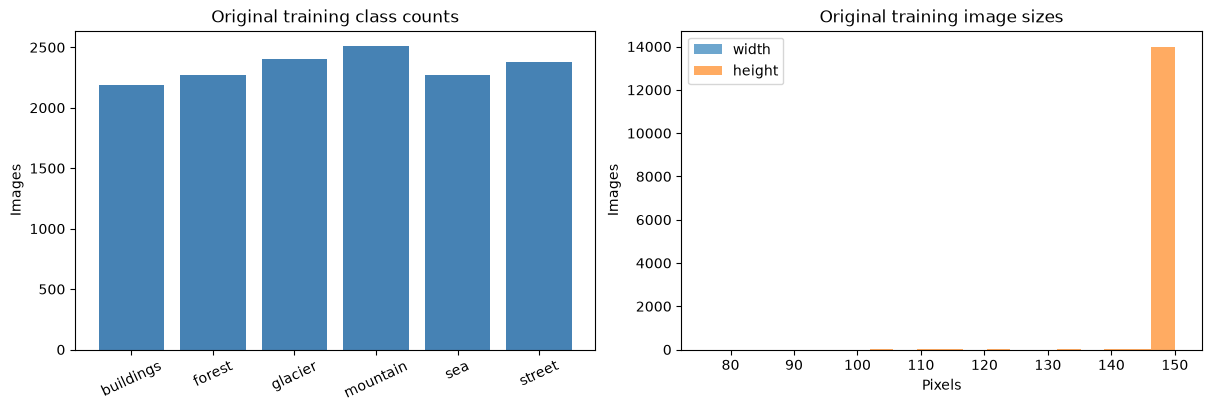

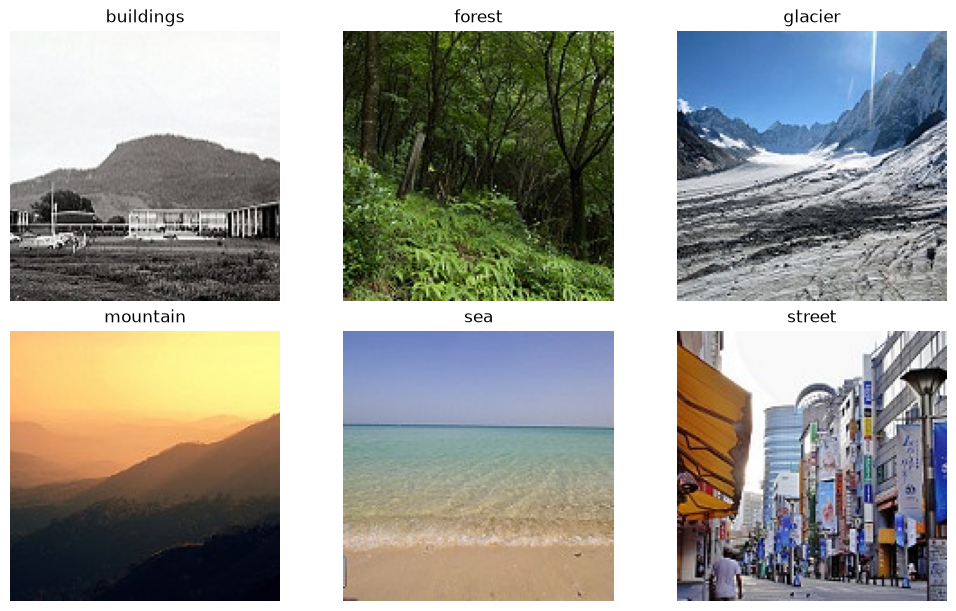

In [2]:
development = [r for r in manifest if r['split'] != 'test']
original_train = development + audit['removed_train_duplicates']
assert len(original_train) == audit['original_train'] == 14034
original_counts = Counter(r['class_name'] for r in original_train)
sizes = np.array([[int(r['width']), int(r['height'])] for r in original_train])
table([{'class': c, 'original_train': original_counts[c]} for c in CLASSES])
print('Modes:', dict(Counter(r['original_mode'] for r in original_train)))
print('Min/median/max width:', sizes[:,0].min(), np.median(sizes[:,0]), sizes[:,0].max())
print('Min/median/max height:', sizes[:,1].min(), np.median(sizes[:,1]), sizes[:,1].max())
fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)
axes[0].bar(CLASSES, [original_counts[c] for c in CLASSES], color='steelblue')
axes[0].set(title='Original training class counts', ylabel='Images')
axes[0].tick_params(axis='x', rotation=25)
axes[1].hist(sizes[:,0], bins=20, alpha=.65, label='width')
axes[1].hist(sizes[:,1], bins=20, alpha=.65, label='height')
axes[1].set(title='Original training image sizes', xlabel='Pixels', ylabel='Images')
axes[1].legend()
fig.savefig(OUT / 'eda.png', dpi=150); plt.show()

fig, axes = plt.subplots(2, 3, figsize=(10, 6), constrained_layout=True)
for ax, name in zip(axes.flat, CLASSES):
    row = next(r for r in original_train if r['class_name'] == name)
    with PILImage.open(RAW / row['relative_path']) as im:
        ax.imshow(im.convert('RGB'))
    ax.set_title(name); ax.axis('off')
plt.show()

## 03. DATA SPLIT — Thiết kế và kiểm tra tập dữ liệu

Ba tập dữ liệu có vai trò khác nhau: **train** dùng cập nhật trọng số, **validation** dùng so sánh cấu hình và chọn checkpoint, còn **test** ước lượng hiệu quả của mô hình đã chọn trên dữ liệu giữ riêng. Sau làm sạch, dữ liệu gồm **11.208 ảnh train, 2.798 validation và 3.000 test**. Chia phân tầng khoảng 80/20 cho phần phát triển giúp tỷ lệ sáu lớp được duy trì giữa train và validation; seed 42 giúp tái tạo cách chia.

Kiểm tra cả đường dẫn lẫn SHA256 giữa các tập nhằm phát hiện ảnh trùng dù tên file khác nhau. Nếu một ảnh xuất hiện ở cả train và validation/test, điểm đánh giá có thể cao do mô hình đã gặp chính ảnh đó. Vì vậy, xử lý trùng là tiền điều kiện của split cuối cùng, dù phần giải thích Cleaning được trình bày ở mục kế tiếp.

In [3]:
split_rows = {s: [r for r in manifest if r['split'] == s] for s in ('train','validation','test')}
split_hashes = {s: {r['sha256'] for r in rows} for s, rows in split_rows.items()}
split_paths = {s: {r['relative_path'] for r in rows} for s, rows in split_rows.items()}
for a,b in [('train','validation'),('train','test'),('validation','test')]:
    assert not split_hashes[a] & split_hashes[b], (a,b,'hash leakage')
    assert not split_paths[a] & split_paths[b], (a,b,'path leakage')
table([{'class': c, **{s: sum(r['class_name']==c for r in rows) for s,rows in split_rows.items()}} for c in CLASSES])
print('Tổng:', {s: len(rows) for s,rows in split_rows.items()}, '| Không giao path/SHA256.')
assert [len(split_rows[s]) for s in ('train','validation','test')] == [11208,2798,3000]

class,train,validation,test
buildings,1750,437,437
forest,1816,453,474
glacier,1919,479,553
mountain,2004,500,525
sea,1818,454,510
street,1901,475,501


Tổng: {'train': 11208, 'validation': 2798, 'test': 3000} | Không giao path/SHA256.


## 04. CLEANING — Làm sạch có kiểm chứng

Ảnh lỗi, ảnh trùng và nhãn mâu thuẫn có thể làm sai lệch quá trình học. Kết quả kiểm tra phát hiện **13 nhóm ảnh giống byte nhưng khác nhãn**. Một nội dung hình ảnh gắn với nhiều mục tiêu tạo ra tín hiệu học không nhất quán, đặc biệt ở những lớp vốn có đặc điểm gần nhau.

Có 23 ảnh training thuộc các nhóm mâu thuẫn được loại khỏi danh sách sử dụng; cộng thêm trùng lặp hoặc chồng lấn test, tổng số bản ghi training bị loại là **28**. Dữ liệu gốc và tập test được giữ lại để bảo đảm khả năng đối chiếu. SHA256 xác nhận tính toàn vẹn và phát hiện trùng byte, nhưng ảnh đã nén lại, cắt hoặc chỉnh màu có thể có hash khác dù nội dung gần giống; do đó đây chưa phải kiểm tra toàn diện ảnh tương tự.

In [4]:
conflicts = read_json(ROOT / 'outputs/data/label_conflicts.json')
removed = audit['removed_train_duplicates']
assert len(conflicts) == 13 and len(removed) == 28
table([{'reason': reason, 'count': count} for reason,count in Counter(r['reason'] for r in removed).items()])
assert len({r['sha256'] for r in development}) == len(development)
for i,row in enumerate(manifest, 1):
    if sha256(RAW / row['relative_path']) != row['sha256']:
        raise ValueError('Ảnh raw đã thay đổi: '+row['relative_path'])
print('Đã xác minh SHA256 của', len(manifest), 'ảnh giữ lại; raw không thay đổi.')
table([{'path':r['relative_path'], 'class':r['class_name'], 'reason':r['reason']} for r in removed[:8]])

reason,count
conflicting_labels,23
duplicate_or_test_overlap,5


Đã xác minh SHA256 của 17006 ảnh giữ lại; raw không thay đổi.


path,class,reason
seg_train/seg_train/buildings/4551.jpg,buildings,conflicting_labels
seg_train/seg_train/buildings/4634.jpg,buildings,conflicting_labels
seg_train/seg_train/buildings/5069.jpg,buildings,conflicting_labels
seg_train/seg_train/buildings/9769.jpg,buildings,conflicting_labels
seg_train/seg_train/forest/18807.jpg,forest,duplicate_or_test_overlap
seg_train/seg_train/forest/8689.jpg,forest,duplicate_or_test_overlap
seg_train/seg_train/glacier/10234.jpg,glacier,conflicting_labels
seg_train/seg_train/glacier/16044.jpg,glacier,conflicting_labels


## 05. FEATURE ENGINEERING — Tiền xử lý và đặc trưng học sẵn

Tiền xử lý đưa ảnh về dạng phù hợp với mạng pretrained: chuyển RGB, resize cạnh ngắn lên 256, crop 224×224, chuyển thành tensor và chuẩn hóa bằng mean/std ImageNet. Chuẩn hóa giúp đầu vào tương thích với phân bố mà trọng số pretrained đã được học. Random crop và horizontal flip ở train tạo biến thể vị trí/hướng nhìn; center crop ở validation/test giữ phép đánh giá nhất quán.

CNN tự học biểu diễn từ cạnh và kết cấu tới hình dạng phức tạp. Với DenseNet121 đóng băng, mỗi ảnh được biểu diễn bằng **vector 1.024 chiều**, sau đó một lớp tuyến tính học ranh giới giữa sáu lớp. Backbone này chỉ dùng trọng số ImageNet, nên việc trích trước đặc trưng cho cross-validation không học thông tin nhãn của fold giữ lại. Đặc trưng center-crop cố định trong CV cũng tạo ra một điều kiện học khác với augmentation ngẫu nhiên của các run transfer.

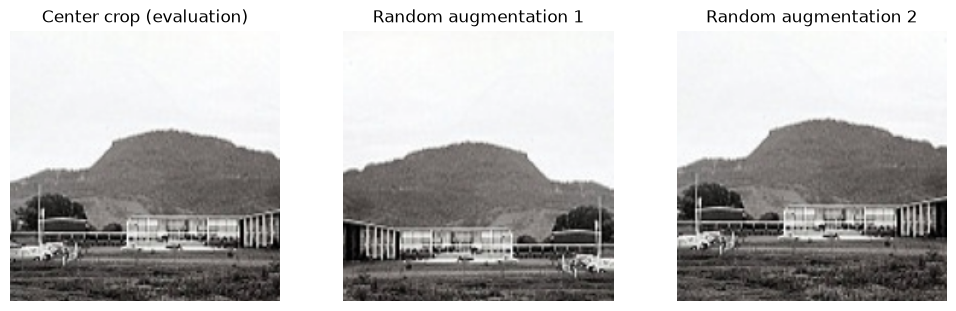

In [5]:
MEAN = torch.tensor([.485,.456,.406]).view(3,1,1)
STD = torch.tensor([.229,.224,.225]).view(3,1,1)
eval_transform = DenseNet121_Weights.IMAGENET1K_V1.transforms()
train_transform = transforms.Compose([transforms.Resize(256),transforms.RandomCrop(224),
    transforms.RandomHorizontalFlip(),transforms.ToTensor(),transforms.Normalize(MEAN.flatten().tolist(),STD.flatten().tolist())])
example = RAW / split_rows['train'][0]['relative_path']
with PILImage.open(example) as im:
    rgb = im.convert('RGB')
    views = [eval_transform(rgb),train_transform(rgb),train_transform(rgb)]
assert all(t.shape == (3,224,224) and torch.isfinite(t).all() for t in views)
fig,axes = plt.subplots(1,3,figsize=(10,3),constrained_layout=True)
for ax,t,title in zip(axes,views,['Center crop (evaluation)','Random augmentation 1','Random augmentation 2']):
    ax.imshow((t*STD+MEAN).clamp(0,1).permute(1,2,0)); ax.set_title(title); ax.axis('off')
plt.show()

## 06. BASELINE MODEL — Mốc so sánh đơn giản

Baseline là mốc tối thiểu để biết mô hình có khai thác thông tin ảnh hay chỉ tận dụng phân bố nhãn. Majority-class baseline luôn dự đoán **mountain**, lớp nhiều nhất trong train. Trên validation, cách này đạt **17,87% accuracy** nhưng macro-F1 chỉ khoảng **0,0505**, vì năm lớp còn lại không được nhận diện đúng.

Đoán đều ngẫu nhiên giữa sáu lớp có accuracy kỳ vọng **16,67%**. Khoảng cách lớn giữa các mốc này và accuracy trên 90% của mạng pretrained cho thấy mô hình học được thông tin phân biệt từ ảnh. Tuy nhiên, vượt baseline đơn giản chỉ là kiểm tra ban đầu; việc chọn giữa các kiến trúc cần so sánh trên cùng dữ liệu và điều kiện huấn luyện.

In [6]:
train_counts = Counter(int(r['label']) for r in split_rows['train'])
majority_label = max(range(6),key=lambda i:(train_counts[i],-i))
y_val = np.array([int(r['label']) for r in split_rows['validation']])
baseline_cm = np.zeros((6,6),dtype=int)
np.add.at(baseline_cm,(y_val,np.full(len(y_val),majority_label)),1)
baseline = metrics(baseline_cm)
assert baseline['samples'] == len(y_val)
table([{'baseline':'Majority: '+CLASSES[majority_label], 'validation_accuracy':baseline['accuracy'], 'macro_f1':baseline['macro_f1']},
       {'baseline':'Uniform random (theoretical expectation)', 'validation_accuracy':1/6, 'macro_f1':'Không giả lập'}])

baseline,validation_accuracy,macro_f1
Majority: mountain,0.17869907076483202,0.0505356781888013
Uniform random (theoretical expectation),0.16666666666666666,Không giả lập


## 07. MODEL SELECTION — Chọn tập ứng viên

**VGG11** dùng các lớp convolution/pooling nối tiếp và phần classifier lớn; **DenseNet121** nối đặc trưng từ các lớp trước trong mỗi dense block, tạo điều kiện tái sử dụng thông tin. Sau khi thay đầu ra thành sáu lớp, VGG11 có khoảng **128,79 triệu tham số**, còn DenseNet121 khoảng **6,96 triệu**. Chênh lệch này ảnh hưởng đến dung lượng lưu trữ và bộ nhớ, nhưng tốc độ còn phụ thuộc phép toán, batch và phần cứng.

Ở transfer learning, chỉ linear cuối được cập nhật: 24.582 tham số với VGG11 và 6.150 với DenseNet121. Cách này tận dụng biểu diễn có sẵn và hạn chế số tham số phải ước lượng từ dataset nhỏ. Khi mở block cuối để fine-tune, mô hình có thêm khả năng thích nghi đặc trưng với phong cảnh, đồng thời tăng nhu cầu tính toán và nguy cơ overfitting.

In [7]:
preflight = read_json(ROOT / 'outputs/models/preflight.json')
table([{'model':r['model'],'mode':r['mode'],'total_parameters':r['parameters_total'],
        'trainable_parameters':r['parameters_trainable']} for r in preflight['records'] if r['batch']==8])
table([{'run':r['id'],'model':r['spec']['model'],'baseline_val_accuracy':r['best']['val_accuracy']}
       for r in runs if r['id'] in ('R01','R04')])
print('Hàm tạo model đã dùng trong WF-002:')
print(inspect.getsource(build))

model,mode,total_parameters,trainable_parameters
vgg11,transfer,128790918,24582
vgg11,finetune,128790918,4744198
densenet121,transfer,6960006,6150
densenet121,finetune,6960006,2166278


run,model,baseline_val_accuracy
R01,vgg11,0.9099356683345247
R04,densenet121,0.9102930664760543


Hàm tạo model đã dùng trong WF-002:
def build(name, mode='transfer', seed=42):
    if name not in WEIGHTS or mode not in ('transfer', 'finetune'):
        raise ValueError((name, mode))
    torch.manual_seed(seed)
    torch.hub.set_dir(str(ROOT / 'data/weights'))
    model = (vgg11 if name == 'vgg11' else densenet121)(weights=WEIGHTS[name])
    model.requires_grad_(False)
    if name == 'vgg11':
        model.classifier[-1] = nn.Linear(model.classifier[-1].in_features, 6)
        if mode == 'finetune':
            model.features[16:].requires_grad_(True)
    else:
        model.classifier = nn.Linear(model.classifier.in_features, 6)
        if mode == 'finetune':
            model.features.denseblock4.requires_grad_(True)
            model.features.norm5.requires_grad_(True)
    model.eval()
    return model



## 08. HYPERPARAMETER TUNING — So sánh cấu hình

Learning rate quyết định độ lớn bước cập nhật, còn batch size ảnh hưởng đến số mẫu dùng ước lượng gradient và số lần cập nhật trong một epoch. Ba cấu hình cho mỗi kiến trúc gồm **LR 0,001/batch 8**, **LR 0,0003/batch 8** và **LR 0,001/batch 16**. Giữ Adam, seed và ngân sách 5 epoch giúp so sánh từng thay đổi với baseline cùng kiến trúc.

Giảm LR giúp VGG11 tăng validation accuracy từ **90,99% lên 91,53%**, còn tăng batch lên 16 đạt **91,24%**. Với DenseNet121, các mức tương ứng là **91,03%, 91,10% và 91,21%**. Như vậy, cấu hình tốt phụ thuộc kiến trúc; trong lượt thử này, **R02 — VGG11, LR 0,0003, batch 8** đạt validation cao nhất trong sáu run transfer. Những chênh lệch nhỏ vẫn cần nhiều seed để đánh giá độ ổn định.

In [8]:
table([{'run':r['id'],'architecture':r['spec']['model'],'lr':r['spec']['lr'],'batch':r['spec']['batch'],
        'best_epoch':r['best']['epoch'],'val_accuracy':r['best']['val_accuracy'],'val_loss':r['best']['val_loss']}
       for r in runs[:6]])
transfer_winner = min(runs[:6],key=lambda r:score(r['best']))
assert transfer_winner['id'] == selection['best_transfer']
print('Thắng transfer bằng validation:',transfer_winner['id'],transfer_winner['spec'])

run,architecture,lr,batch,best_epoch,val_accuracy,val_loss
R01,vgg11,0.001,8,5,0.9099356683345247,0.3007435174843264
R02,vgg11,0.0003,8,5,0.9152966404574696,0.23594580607958407
R03,vgg11,0.001,16,5,0.9124374553252323,0.26259042246404
R04,densenet121,0.001,8,2,0.9102930664760543,0.22992725744867615
R05,densenet121,0.0003,8,5,0.9110078627591136,0.23133449624721933
R06,densenet121,0.001,16,3,0.9120800571837027,0.23673135055105246


Thắng transfer bằng validation: R02 {'id': 'R02', 'model': 'vgg11', 'mode': 'transfer', 'lr': 0.0003, 'batch': 8, 'epochs': 5}


## 09. TRAIN MODEL 

Huấn luyện gồm hai giai đoạn: học đầu phân loại trên backbone đóng băng, sau đó fine-tune block cuối để đặc trưng thích nghi sâu hơn với bài toán. R07 bắt đầu từ checkpoint R02, dùng Adam mới với LR **0,00001** và học thêm **3 epoch**. LR nhỏ giúp điều chỉnh trọng số pretrained từng bước, hạn chế làm mất các đặc trưng hữu ích đã học.

Đường học của R07 cho thấy train loss giảm từ khoảng **0,1211 xuống 0,0837**, trong khi validation accuracy tăng từ **91,74% lên 92,03%**. Tuy nhiên, validation loss tăng từ khoảng **0,2378 lên 0,2494**. Điều này có thể xảy ra khi số ảnh đúng tăng nhưng một số dự đoán sai trở nên tự tin hơn; vì vậy cần theo dõi cả loss và accuracy để nhận diện nguy cơ overfitting. Các chỉ số được tổng hợp theo số mẫu, giúp batch cuối ít ảnh vẫn có trọng số phù hợp.

def epoch(model, batches, device, optimizer=None):
    # Frozen dropout and BatchNorm statistics stay fixed in both phases.
    model.eval()
    total_loss, correct, count = 0.0, 0, 0
    synchronize(device)
    started = time.perf_counter()
    with torch.set_grad_enabled(optimizer is not None):
        for step, (images, labels) in enumerate(batches, 1):
            images, labels = images.to(device), labels.to(device)
            if optimizer is not None:
                optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = torch.nn.functional.cross_entropy(logits, labels)
            if not torch.isfinite(loss).item():
                raise FloatingPointError('Non-finite loss')
            if optimizer is not None:
                loss.backward()
                verify_gradients(model)
                optimizer.step()
            total_loss += loss.item() * len(labels)
            correct += (logits.argmax(1) == labels).sum().item()
           

VERIFIED: 7 run / 33 epoch và checksum best.pt/last.pt.


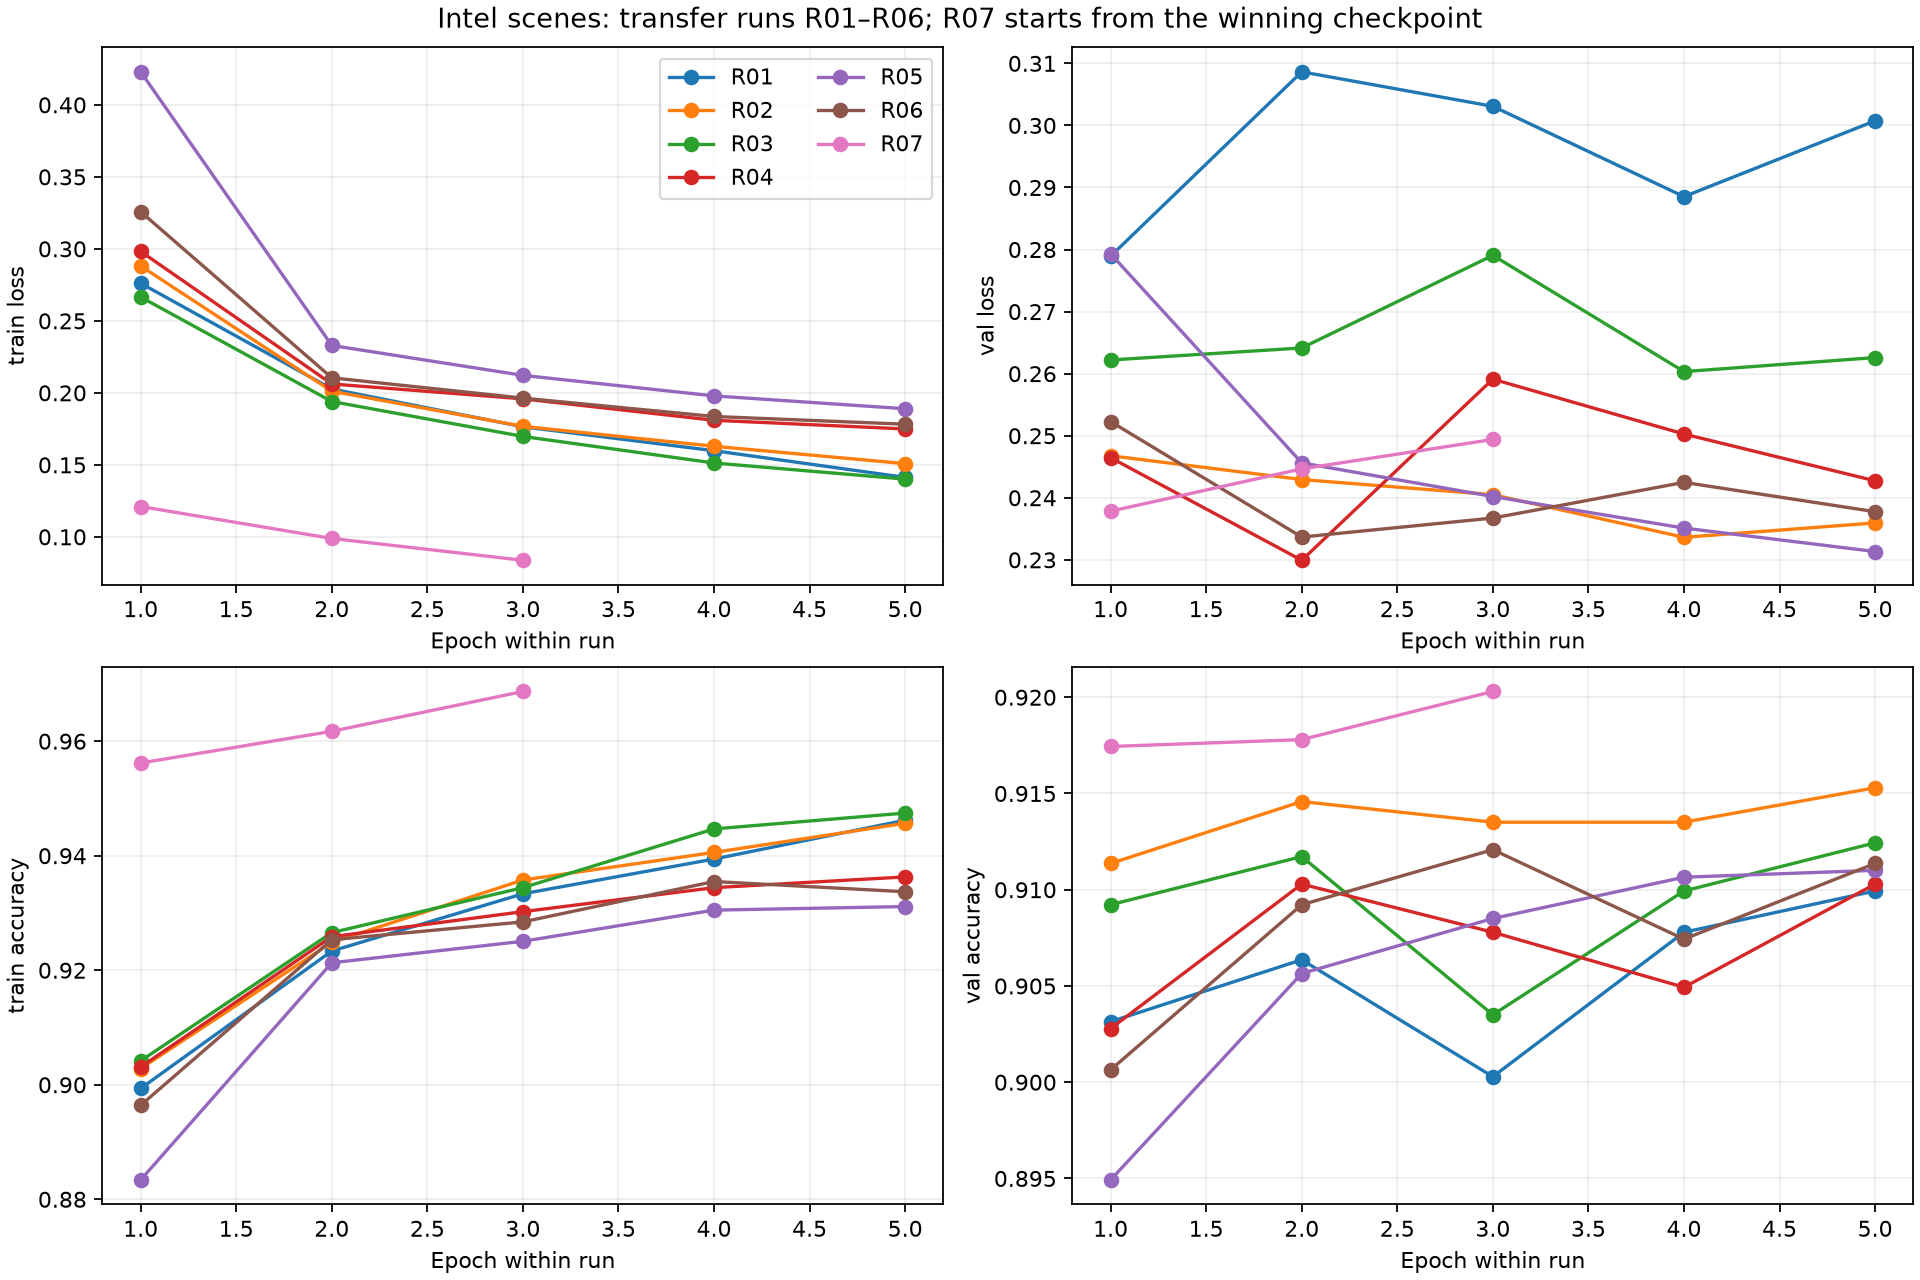

In [9]:
from src.phases import phase_04_train
RUN_EXISTING_TRAIN_PIPELINE = False
print(inspect.getsource(phase_04_train.epoch))
if RUN_EXISTING_TRAIN_PIPELINE:
    phase_04_train.run()
for result in runs:
    folder = ROOT / 'outputs/experiments' / result['id']
    for name,checksum in result['checkpoint_hashes'].items():
        assert sha256(folder/name)==checksum,(result['id'],name)
    assert len(result['history'])==result['spec']['epochs']
assert sum(len(r['history']) for r in runs)==33
print('VERIFIED: 7 run / 33 epoch và checksum best.pt/last.pt.')
display(Image(filename=str(ROOT/'outputs/report/learning_curves.png')))

## 10. EVALUATION METRICS — Đánh giá trên test giữ riêng

**Accuracy** cho biết tỷ lệ ảnh phân loại đúng. **Precision** đo mức chính xác khi mô hình dự đoán một lớp; **recall** đo tỷ lệ ảnh thật của lớp đó được tìm đúng. F1 cân bằng precision và recall, còn macro-F1 trung bình F1 của sáu lớp với trọng số bằng nhau. Confusion matrix đặt nhãn thật theo hàng và dự đoán theo cột, giúp xác định lỗi tập trung ở đâu.

Trên 3.000 ảnh test, R02 đạt **91,70% accuracy**, R06 đạt **91,53%** và R07 đạt **92,80%**, tương ứng macro-F1 **0,9186; 0,9168; 0,9297**. R07 phân loại đúng **2.784 ảnh**, còn 216 lỗi. Accuracy tổng thể cần được đọc cùng chỉ số từng lớp: chẳng hạn recall forest đạt **99,16%**, trong khi glacier chỉ đạt **84,63%**, cho thấy độ khó giữa các lớp khác nhau đáng kể.

run,accuracy,macro_f1,samples
R02,0.917,0.9185855154809796,3000
R06,0.9153333333333333,0.9168470600070399,3000
R07,0.928,0.9297179852881522,3000


name,precision,recall,f1,support
buildings,0.927765237020316,0.9405034324942791,0.934090909090909,437
forest,0.9873949579831933,0.9915611814345991,0.9894736842105263,474
glacier,0.896551724137931,0.8462929475587704,0.8706976744186047,553
mountain,0.8653136531365314,0.8933333333333333,0.8791002811621369,525
sea,0.9521072796934866,0.9745098039215686,0.9631782945736435,510
street,0.9474747474747475,0.936127744510978,0.9417670682730923,501


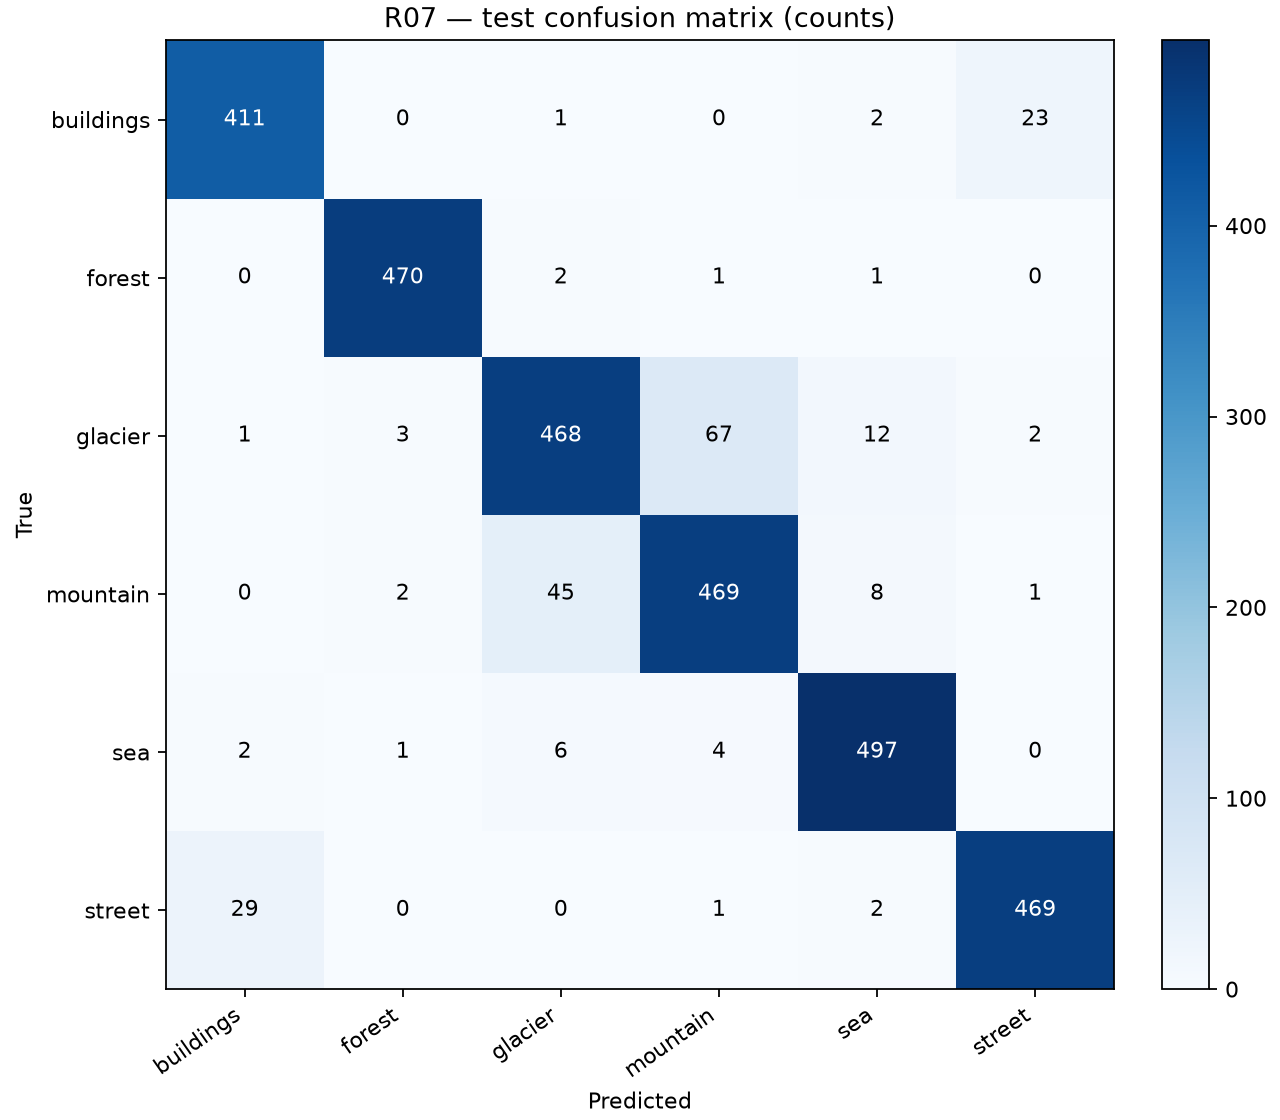

In [10]:
predictions = {}
test_results = {}
for run_id in selection['test_runs']:
    saved = read_json(ROOT/f'outputs/report/{run_id}_test.json')
    path = ROOT/f'outputs/report/{run_id}_predictions.csv'
    assert sha256(path)==saved['predictions_sha256']
    rows = sorted(read_csv(path),key=lambda r:r['relative_path'])
    truth = np.array([int(r['truth']) for r in rows])
    predicted = np.array([int(r['prediction']) for r in rows])
    cm = np.zeros((6,6),dtype=int); np.add.at(cm,(truth,predicted),1)
    values = metrics(cm)
    assert values['accuracy']==saved['accuracy'] and values['macro_f1']==saved['macro_f1']
    assert len(rows)==3000 and selection['selected_before_test'] <= saved['evaluated']
    predictions[run_id] = rows; test_results[run_id] = values
table([{'run':k,'accuracy':v['accuracy'],'macro_f1':v['macro_f1'],'samples':v['samples']} for k,v in test_results.items()])
table(test_results[selection['final_run']]['per_class'])
display(Image(filename=str(ROOT/f'outputs/report/{selection["final_run"]}_confusion_matrix.png')))

## 11. CROSS VALIDATION 

Cross-validation đánh giá độ nhạy của kết quả với cách chia dữ liệu bằng cách lần lượt giữ lại từng fold để kiểm tra. Ở đây, 14.006 ảnh thuộc phần phát triển được chia phân tầng thành **5 fold**. Mỗi lượt dùng bốn fold để học linear head mới trên đặc trưng DenseNet121 đóng băng, rồi dự đoán fold còn lại. Mỗi ảnh vì thế có đúng một dự đoán **out-of-fold**, được tạo bởi head chưa học từ ảnh đó.

Với center crop, Adam LR 0,001, batch 256 và 5 epoch/fold, accuracy trung bình đạt **91,65%**, độ lệch chuẩn mẫu khoảng **0,41 điểm phần trăm**; các fold dao động từ **90,96% đến 92,00%**. Độ dao động này mô tả ảnh hưởng của cách chia trong thí nghiệm linear probe. Nó không phải khoảng tin cậy và không đại diện cho CV của VGG11 fine-tune R07, vốn dùng kiến trúc và cách huấn luyện khác. Đánh giá cả quá trình lựa chọn siêu tham số cần thiết kế như nested CV để tách dữ liệu chọn cấu hình khỏi dữ liệu đánh giá.

In [11]:
CV_PROTOCOL = {'name':'densenet121_frozen_center_crop_linear_probe_v1','folds':5,'epochs':5,
               'lr':.001,'batch':256,'seed':42,'feature_batch':16}
cv_rows = sorted(development,key=lambda r:r['relative_path'])
cv_y = np.array([int(r['label']) for r in cv_rows])
cv_id = fingerprint({'protocol':CV_PROTOCOL,'manifest':sha256(MANIFEST),
                     'weights':read_json(ROOT/'outputs/models/weights.json')['densenet121'],
                     'torch':torch.__version__})
fold_id = np.full(len(cv_rows),-1,dtype=int)
generator = np.random.default_rng(SEED)
for label in range(6):
    indices = np.flatnonzero(cv_y==label); generator.shuffle(indices)
    for f,group in enumerate(np.array_split(indices,5)):
        fold_id[group]=f
assert np.all(fold_id>=0)
assert not {r['sha256'] for r in cv_rows} & split_hashes['test']
for f in range(5):
    a={cv_rows[i]['sha256'] for i in np.flatnonzero(fold_id!=f)}
    b={cv_rows[i]['sha256'] for i in np.flatnonzero(fold_id==f)}
    assert not a & b
table([{'fold':f+1,'train':int((fold_id!=f).sum()),'held_out':int((fold_id==f).sum())} for f in range(5)])

class FeatureImages(Dataset):
    def __len__(self): return len(cv_rows)
    def __getitem__(self,index):
        with PILImage.open(RAW/cv_rows[index]['relative_path']) as im:
            return eval_transform(im.convert('RGB'))

feature_file = OUT/'densenet_features.pt'
feature_meta = OUT/'densenet_features.json'
if feature_file.exists() and feature_meta.exists():
    metadata = read_json(feature_meta)
    assert metadata['fingerprint']==cv_id and metadata['sha256']==sha256(feature_file),'Stale feature cache'
    features = torch.load(feature_file,map_location='cpu',weights_only=True)
else:
    backbone = build('densenet121','transfer',SEED)
    backbone.classifier = nn.Identity()
    backbone.requires_grad_(False).eval().to(DEVICE)
    collected = []
    with torch.no_grad():
        for step,images in enumerate(DataLoader(FeatureImages(),batch_size=16,shuffle=False,num_workers=0),1):
            collected.append(backbone(images.to(DEVICE)).cpu())
            if step%100==0: print('Feature extraction:',min(step*16,len(cv_rows)),'/',len(cv_rows),flush=True)
    features = torch.cat(collected)
    temporary = feature_file.with_suffix('.tmp'); torch.save(features,temporary); temporary.replace(feature_file)
    write_json(feature_meta,{'fingerprint':cv_id,'sha256':sha256(feature_file),'created':now()})
    del backbone,collected; gc.collect()
    if DEVICE=='xpu': torch.xpu.empty_cache()
assert features.shape==(len(cv_rows),1024) and torch.isfinite(features).all()
print('Frozen features:',tuple(features.shape),'| no test images')

fold,train,held_out
1,11202,2804
2,11203,2803
3,11205,2801
4,11206,2800
5,11208,2798


Feature extraction: 1600 / 14006


Feature extraction: 3200 / 14006


Feature extraction: 4800 / 14006


Feature extraction: 6400 / 14006


Feature extraction: 8000 / 14006


Feature extraction: 9600 / 14006


Feature extraction: 11200 / 14006


Feature extraction: 12800 / 14006


Frozen features: (14006, 1024) | no test images


In [12]:
cv_cache = OUT/'cross_validation.json'
oof_path = OUT/'cv_oof.csv'
if cv_cache.exists():
    cv_result = read_json(cv_cache)
    assert cv_result['fingerprint']==cv_id and cv_result['oof_sha256']==sha256(oof_path),'Stale CV cache'
    oof_rows = read_csv(oof_path)
    assert [r['relative_path'] for r in oof_rows]==[r['relative_path'] for r in cv_rows]
    oof = np.array([int(r['prediction']) for r in oof_rows])
    assert np.array_equal([int(r['fold']) for r in oof_rows],fold_id+1)
else:
    oof = np.full(len(cv_y),-1,dtype=int)
    fold_results = []
    previous_threads = torch.get_num_threads()
    torch.set_num_threads(2)  # Small linear heads avoid large CPU thread-pool overhead.
    try:
        for f in range(5):
            torch.manual_seed(SEED+f)
            train_indices=np.flatnonzero(fold_id!=f); held_indices=np.flatnonzero(fold_id==f)
            head=nn.Linear(1024,6)
            optimizer=torch.optim.Adam(head.parameters(),lr=.001)
            batches=DataLoader(TensorDataset(features[train_indices],torch.tensor(cv_y[train_indices])),
                               batch_size=256,shuffle=True,generator=torch.Generator().manual_seed(SEED+f))
            with SummaryWriter(str(OUT/f'tensorboard/cv_fold_{f+1}'),purge_step=0) as writer:
                for ep in range(1,6):
                    total_loss=0.; samples=0
                    head.train()
                    for x,y in batches:
                        optimizer.zero_grad(set_to_none=True)
                        loss=nn.functional.cross_entropy(head(x),y)
                        assert torch.isfinite(loss)
                        loss.backward(); optimizer.step()
                        total_loss+=loss.item()*len(y); samples+=len(y)
                    writer.add_scalar('train/loss',total_loss/samples,ep)
                head.eval()
                with torch.no_grad():
                    oof[held_indices]=head(features[held_indices]).argmax(1).numpy()
                cm=np.zeros((6,6),dtype=int); np.add.at(cm,(cv_y[held_indices],oof[held_indices]),1)
                result=metrics(cm)
                row={'fold':f+1,'samples':len(held_indices),'accuracy':result['accuracy'],'macro_f1':result['macro_f1']}
                fold_results.append(row)
                writer.add_scalar('held_out/accuracy',row['accuracy'],5)
                writer.add_scalar('held_out/macro_f1',row['macro_f1'],5)
                print('CV:',row,flush=True)
            del head,optimizer,batches
    finally:
        torch.set_num_threads(previous_threads)
    with oof_path.open('w',encoding='utf-8',newline='') as f:
        w=csv.DictWriter(f,fieldnames=['relative_path','fold','truth','prediction']); w.writeheader()
        w.writerows({'relative_path':r['relative_path'],'fold':int(fold_id[i]+1),'truth':int(cv_y[i]),'prediction':int(oof[i])}
                    for i,r in enumerate(cv_rows))
    cv_result={'status':'COMPLETED','fingerprint':cv_id,'protocol':CV_PROTOCOL,'created':now(),
               'fold_results':fold_results,'oof_sha256':sha256(oof_path)}
    write_json(cv_cache,cv_result)
assert oof.shape==cv_y.shape and np.all((oof>=0)&(oof<6))
assert len(read_csv(oof_path))==len(cv_rows)==14006
for row in cv_result['fold_results']:
    mask=fold_id==row['fold']-1
    assert np.isclose((oof[mask]==cv_y[mask]).mean(),row['accuracy'])
cv_scores=np.array([r['accuracy'] for r in cv_result['fold_results']])
table(cv_result['fold_results'])
print(f'Linear-probe CV accuracy: mean={cv_scores.mean():.2%}, sample SD={cv_scores.std(ddof=1):.2%}')
print('Đây KHÔNG phải CV accuracy của R07.')

CV: {'fold': 1, 'samples': 2804, 'accuracy': 0.9165477888730386, 'macro_f1': 0.9181282049602215}


CV: {'fold': 2, 'samples': 2803, 'accuracy': 0.9172315376382447, 'macro_f1': 0.9188419177696368}


CV: {'fold': 3, 'samples': 2801, 'accuracy': 0.9189575151731525, 'macro_f1': 0.9199838977186485}


CV: {'fold': 4, 'samples': 2800, 'accuracy': 0.92, 'macro_f1': 0.9216342752043204}


CV: {'fold': 5, 'samples': 2798, 'accuracy': 0.909578270192995, 'macro_f1': 0.9111899383754731}


fold,samples,accuracy,macro_f1
1,2804,0.9165477888730386,0.9181282049602215
2,2803,0.9172315376382447,0.9188419177696368
3,2801,0.9189575151731525,0.9199838977186485
4,2800,0.92,0.9216342752043204
5,2798,0.909578270192995,0.9111899383754731


Linear-probe CV accuracy: mean=91.65%, sample SD=0.41%
Đây KHÔNG phải CV accuracy của R07.


## 12. EXPERIMENT MANAGEMENT — Quản lý và truy vết

Quản lý thí nghiệm giúp mỗi kết quả gắn với đúng kiến trúc, siêu tham số, dữ liệu và phiên bản code. Nếu chỉ lưu accuracy, rất khó phân biệt một thay đổi có lợi đến từ LR, batch, split hay môi trường chạy. Run ID, cấu hình và các giá trị hash tạo cơ sở đối chiếu những yếu tố này giữa các lượt thử.

Checkpoint **best** lưu trạng thái có kết quả validation tốt nhất, còn **last** phục vụ tiếp tục huấn luyện. Optimizer và RNG states giúp khôi phục quá trình học sát trạng thái trước khi gián đoạn. TensorBoard đặt các đường loss/accuracy trên cùng trục epoch để nhận biết tốc độ hội tụ, dao động và khoảng cách train–validation. Thời gian từng run bổ sung góc nhìn chi phí tính toán, nhưng cần xét ảnh hưởng tải máy và phần cứng khi so sánh.

In [13]:
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
tracking=[]
for r in runs:
    directory=ROOT/'outputs/experiments'/r['id']
    identity=read_json(directory/'identity.json')
    assert fingerprint({k:v for k,v in identity.items() if k!='fingerprint'})==r['fingerprint']
    events=EventAccumulator(str(directory/'tensorboard')).Reload()
    for tag in ['train/loss','train/accuracy','validation/loss','validation/accuracy']:
        assert len(events.Scalars(tag))==r['spec']['epochs']
    tracking.append({'run':r['id'],'fingerprint':r['fingerprint'][:16], 'epochs':r['spec']['epochs'],
                     'device':r['device'],'minutes_train_validation':round(r['seconds']/60,2)})
table(tracking)
write_json(OUT/'analysis_manifest.json',{'created':now(),'original_selection_sha256':sha256(ROOT/'outputs/experiments/selection.json'),
          'data_manifest_sha256':sha256(MANIFEST),'cv_fingerprint':cv_id,'seed':SEED,'device_for_new_analysis':DEVICE,
          'original_runs':[r['fingerprint'] for r in runs]})

run,fingerprint,epochs,device,minutes_train_validation
R01,6608b2b74d84326d,5,xpu,19.48
R02,9d9eb0790db243bf,5,xpu,18.0
R03,8e4c942e2c7d8b9e,5,xpu,16.6
R04,74458f4532acb6cf,5,xpu,17.69
R05,2acac0df9595c95e,5,xpu,19.49
R06,a9ee2be6bccf719c,5,xpu,16.72
R07,29922b919ca87cdd,3,xpu,14.32


## 13. STATISTICAL VALIDATION — Khoảng tin cậy và so sánh theo cặp

Đánh giá thống kê giúp lượng hóa mức bất định của điểm số và chênh lệch giữa hai mô hình. Với R07, **Wilson 95% confidence interval** cho test accuracy là khoảng **91,82%–93,67%**. R07 hơn R02 **1,10 điểm phần trăm**; paired bootstrap 2.000 lần, lấy mẫu lại cùng các cặp dự đoán theo ảnh, cho khoảng 95% của chênh lệch khoảng **+0,37 đến +1,77 điểm phần trăm**.

Trong các ảnh mà hai mô hình khác nhau về đúng/sai, có **74 ảnh R07 đúng nhưng R02 sai** và **41 ảnh theo chiều ngược lại**. McNemar exact hai phía cho **p ≈ 0,00269**, cung cấp bằng chứng chống giả thuyết hai chiều bất đồng có xác suất bằng nhau, dưới giả định các cặp ảnh độc lập. Kết quả hỗ trợ mức cải thiện quan sát được trên test này, nhưng đây là phân tích hậu nghiệm; ảnh gần giống có thể làm khoảng tin cậy quá hẹp và phép bootstrap ảnh chưa phản ánh biến thiên do seed huấn luyện.

Tham khảo phương pháp kiểm định nhị thức chính xác: [SciPy binomtest](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.binomtest.html).

In [14]:
def wilson(success,n,confidence=.95):
    assert 0<=success<=n and n>0
    z=NormalDist().inv_cdf((1+confidence)/2); p=success/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    radius=z*math.sqrt(p*(1-p)/n+z*z/(4*n*n))/den
    return max(0.,center-radius),min(1.,center+radius)

def mcnemar_exact(b,c):
    n=int(b+c)
    if n==0: return 1.
    return min(1.,2*sum(math.comb(n,k) for k in range(min(int(b),int(c))+1))/(2**n))

assert abs(mcnemar_exact(10,0)-.001953125)<1e-12
assert mcnemar_exact(0,0)==1 and mcnemar_exact(5,5)==1
assert np.isclose(wilson(0,10)[0],0) and np.isclose(wilson(10,10)[1],1)
a=predictions['R02']; b=predictions['R07']
assert [r['relative_path'] for r in a]==[r['relative_path'] for r in b]
assert [r['truth'] for r in a]==[r['truth'] for r in b]
correct_a=np.array([r['truth']==r['prediction'] for r in a])
correct_b=np.array([r['truth']==r['prediction'] for r in b])
delta=correct_b.astype(float)-correct_a.astype(float)
rng=np.random.default_rng(SEED)
bootstrap=np.concatenate([delta[rng.integers(0,len(delta),size=(100,len(delta)))].mean(axis=1) for _ in range(20)])
bootstrap_ci=np.quantile(bootstrap,[.025,.975])
old_only=int((correct_a & ~correct_b).sum()); new_only=int((~correct_a & correct_b).sum())
statistical={'comparison':'R07 minus R02 (post-hoc paired analysis)', 'n':len(delta),
 'accuracy_R07':float(correct_b.mean()),'wilson_95_accuracy_R07':list(wilson(int(correct_b.sum()),len(delta))),
 'accuracy_difference':float(delta.mean()),'paired_bootstrap_95_difference':bootstrap_ci.tolist(),
 'bootstrap_replicates':2000,'R02_only_correct':old_only,'R07_only_correct':new_only,
 'mcnemar_exact_two_sided_p':mcnemar_exact(old_only,new_only),'seed':SEED}
write_json(OUT/'statistical_validation.json',statistical)
table([{'quantity':k,'value':v} for k,v in statistical.items()])
print(f'Delta={delta.mean()*100:+.2f} điểm %, bootstrap95%=[{bootstrap_ci[0]*100:.2f}, {bootstrap_ci[1]*100:.2f}] điểm %.')
print('Suy luận chỉ áp dụng theo giả định độc lập và phạm vi so sánh hậu nghiệm đã nêu.')

quantity,value
comparison,R07 minus R02 (post-hoc paired analysis)
n,3000
accuracy_R07,0.928
wilson_95_accuracy_R07,"[0.9181926772894202, 0.9367126282017009]"
accuracy_difference,0.011
paired_bootstrap_95_difference,"[0.0036666666666666666, 0.017666666666666667]"
bootstrap_replicates,2000
R02_only_correct,41
R07_only_correct,74
mcnemar_exact_two_sided_p,0.00268570100596285


Delta=+1.10 điểm %, bootstrap95%=[0.37, 1.77] điểm %.
Suy luận chỉ áp dụng theo giả định độc lập và phạm vi so sánh hậu nghiệm đã nêu.


## 14. ERROR ANALYSIS — Phân tích lỗi

Phân tích lỗi chỉ ra những trường hợp mà một con số accuracy tổng hợp chưa giải thích được. Với R07, **67 ảnh glacier bị dự đoán thành mountain** và **45 ảnh mountain thành glacier**. Hai chiều nhầm lẫn này chiếm **112/216 lỗi, khoảng 51,85%**. Cặp buildings–street có tổng **52 lỗi** hai chiều, cũng là nhóm cần chú ý.

Băng tuyết có thể xuất hiện trên núi, còn ảnh đường phố thường chứa nhiều tòa nhà; sự chồng lấn nội dung là một cách giải thích hợp lý cần đối chiếu với từng ảnh. Grid minh họa giúp quan sát bối cảnh, góc chụp và tính mơ hồ của nhãn. Vì các ví dụ được lấy theo thứ tự đường dẫn nên chủ yếu rơi vào lớp buildings; bảng thống kê toàn bộ lỗi mới là cơ sở đánh giá mức phổ biến của từng cặp nhầm lẫn.

true,predicted,count
glacier,mountain,67
mountain,glacier,45
street,buildings,29
buildings,street,23
glacier,sea,12
mountain,sea,8
sea,glacier,6
sea,mountain,4


Số lỗi: 216 / 3000


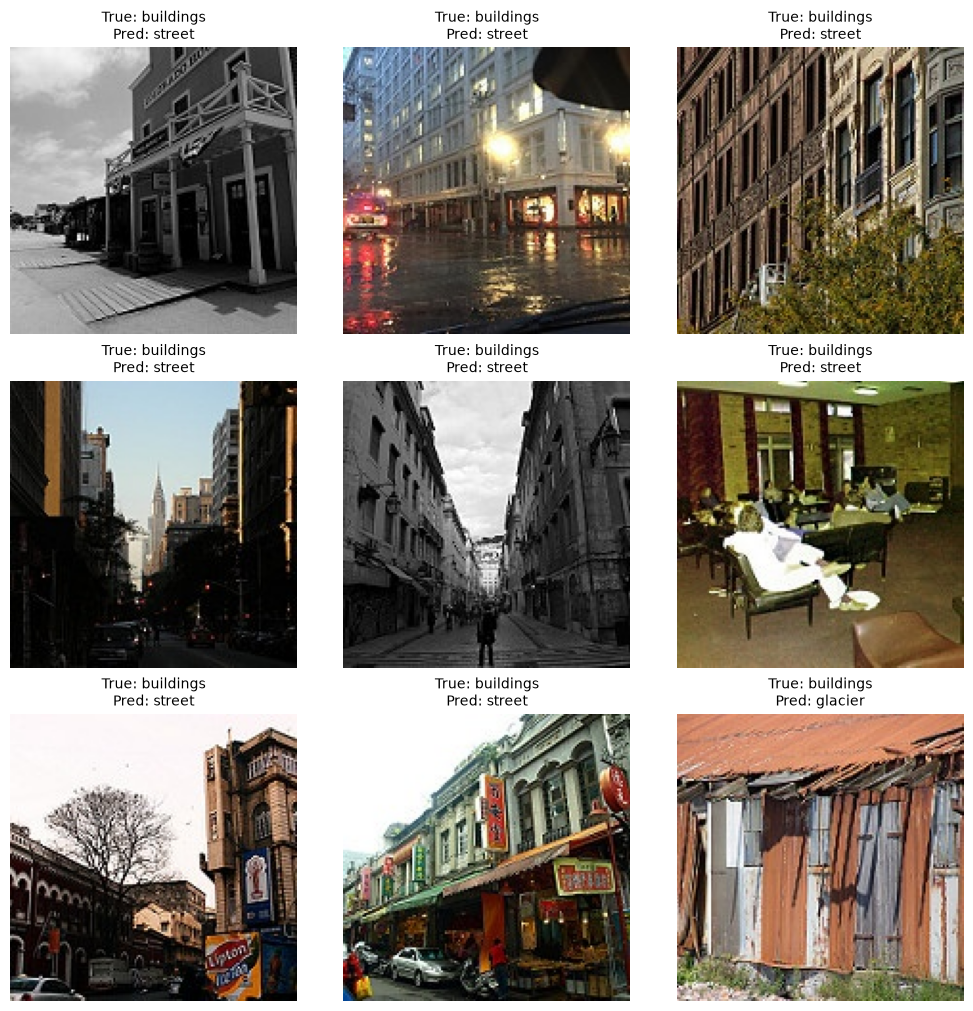

In [15]:
final_id=selection['final_run']
final_predictions=predictions[final_id]
cm=np.array(test_results[final_id]['confusion_matrix'])
pairs=sorted([{'true':CLASSES[i],'predicted':CLASSES[j],'count':int(cm[i,j])}
              for i in range(6) for j in range(6) if i!=j],key=lambda r:-r['count'])
table(pairs[:8])
errors=[r for r in final_predictions if r['truth']!=r['prediction']]
assert len(errors)==int(cm.sum()-cm.trace())
print('Số lỗi:',len(errors),'/',int(cm.sum()))
fig,axes=plt.subplots(3,3,figsize=(10,10),constrained_layout=True)
for ax,row in zip(axes.flat,errors[:9]):
    with PILImage.open(RAW/row['relative_path']) as im: ax.imshow(im.convert('RGB'))
    ax.set_title('True: '+CLASSES[int(row['truth'])]+'\nPred: '+CLASSES[int(row['prediction'])],fontsize=10)
    ax.axis('off')
fig.savefig(OUT/'error_examples.png',dpi=140); plt.show()

## 15. MODEL INTERPRETABILITY — Grad-CAM

**Grad-CAM** giải thích vùng ảnh liên quan đến điểm dự đoán bằng gradient của logit theo activation ở lớp convolution cuối. Trung bình gradient theo không gian tạo trọng số cho các feature map; tổng có trọng số được đưa qua ReLU và nội suy về crop 224×224. Vùng sáng biểu thị đóng góp dương nổi bật trong phép xấp xỉ này, giúp xem mô hình đang dựa vào phần nào của ảnh.

Ví dụ dự đoán đúng buildings cho thấy các vùng được nhấn mạnh nằm trên những phần của mặt ngoài tòa nhà. Ở ví dụ buildings bị dự đoán thành street, vùng sáng nổi bật ở khu vực phía dưới bên trái, nơi có mặt đường và bối cảnh phố. Quan sát này gợi ý ảnh hưởng của bối cảnh đến dự đoán, nhưng không chứng minh quan hệ nhân quả. Heatmap được chuẩn hóa riêng từng ảnh nên độ sáng tuyệt đối không dùng để so sánh mức đóng góp giữa hai ảnh.

Nguồn phương pháp: [bài báo Grad-CAM](https://arxiv.org/abs/1610.02391), [Captum LayerGradCam](https://captum.ai/api/layer.html).

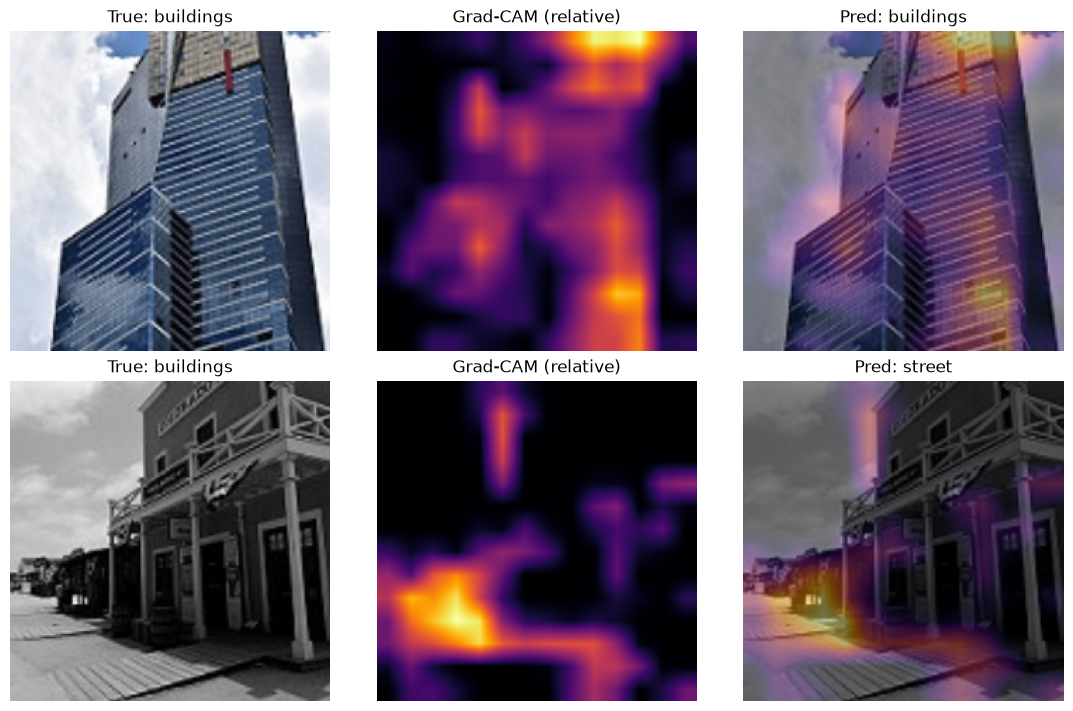

In [16]:
final_run=next(r for r in runs if r['id']==final_id)
best_path=ROOT/'outputs/experiments'/final_id/'best.pt'
assert sha256(best_path)==final_run['checkpoint_hashes']['best.pt']
model=build(final_run['spec']['model'],final_run['spec']['mode'],SEED)
checkpoint=torch.load(best_path,map_location='cpu',weights_only=False)  # Only this verified project-created checkpoint.
model.load_state_dict(checkpoint['model']); del checkpoint
model.requires_grad_(False).eval().to(DEVICE)
assert final_run['spec']['model']=='vgg11','Grad-CAM layer mapping here is for the selected VGG11.'
layer=model.features[18]

def gradcam(row):
    with PILImage.open(RAW/row['relative_path']) as im: x=eval_transform(im.convert('RGB')).unsqueeze(0)
    x=x.to(DEVICE).requires_grad_(True)
    activation=[]
    def capture(module,inputs,output):
        activation.append(output)
        output.retain_grad()
    handle=layer.register_forward_hook(capture)
    try:
        logits=model(x); predicted=int(logits.argmax(1).item())
        model.zero_grad(set_to_none=True)
        logits[0,predicted].backward()
        a=activation[0]
        assert a.grad is not None and torch.isfinite(a.grad).all()
        weights=a.grad.mean(dim=(2,3),keepdim=True)
        heat=torch.relu((weights*a).sum(dim=1,keepdim=True))
        heat=nn.functional.interpolate(heat,size=(224,224),mode='bilinear',align_corners=False)[0,0]
        peak=float(heat.max().item())
        heat=(heat/peak if peak>0 else torch.zeros_like(heat)).detach().cpu().numpy()
        view=(x[0].detach().cpu()*STD+MEAN).clamp(0,1).permute(1,2,0).numpy()
        assert heat.shape==(224,224) and np.isfinite(heat).all()
        return view,heat,predicted,peak
    finally:
        handle.remove()

correct_example=next(r for r in final_predictions if r['truth']==r['prediction'])
cam_examples=[correct_example,errors[0]]
fig,axes=plt.subplots(2,3,figsize=(11,7),constrained_layout=True)
cam_metadata=[]
for axes_row,row in zip(axes,cam_examples):
    view,heat,predicted,peak=gradcam(row)
    assert predicted==int(row['prediction']),'Prediction differs from saved checkpoint evaluation'
    axes_row[0].imshow(view); axes_row[0].set_title('True: '+CLASSES[int(row['truth'])])
    axes_row[1].imshow(heat,cmap='inferno',vmin=0,vmax=1); axes_row[1].set_title('Grad-CAM (relative)')
    axes_row[2].imshow(view); axes_row[2].imshow(heat,cmap='inferno',alpha=.45,vmin=0,vmax=1)
    axes_row[2].set_title('Pred: '+CLASSES[predicted])
    for ax in axes_row: ax.axis('off')
    cam_metadata.append({'path':row['relative_path'],'prediction':predicted,'heatmap_peak_before_normalization':peak})
fig.savefig(OUT/'gradcam.png',dpi=150); plt.show()
write_json(OUT/'gradcam_examples.json',cam_metadata)

## 16. BEST MODEL 

**VGG11 fine-tune R07** là mô hình tốt nhất theo tiêu chí validation accuracy trong các cấu hình đã thử, đạt **92,03%**, cao hơn **91,53%** của checkpoint transfer R02. Việc mở block convolution cuối giúp điều chỉnh các đặc trưng thị giác cho sáu lớp phong cảnh, thay vì chỉ học cách phân loại trên một biểu diễn cố định. R07 có thêm ba epoch huấn luyện nên mức cải thiện cần được xem cùng phần chi phí học bổ sung này.

Trên test, R07 đạt **92,80% accuracy và macro-F1 0,9297**, tương ứng **2.784/3.000 ảnh đúng**, tăng 33 ảnh đúng so với R02. Dù kết quả tổng thể tốt hơn, các lỗi glacier–mountain cho thấy khả năng phân biệt cảnh có nội dung tương tự vẫn còn hạn chế. Vì vậy, “best model” ở đây là lựa chọn tốt nhất trong phạm vi các thí nghiệm, dữ liệu và tiêu chí đã sử dụng, không phải khẳng định ưu thế trên mọi bộ ảnh.

Khi dự đoán ảnh mới, ảnh cần đi qua cùng phép resize, center crop và chuẩn hóa đã dùng khi đánh giá. Mạng trả sáu logits và chọn lớp có giá trị lớn nhất. Checkpoint `best.pt` lưu bộ trọng số đạt validation tốt nhất; dùng đúng checkpoint và tiền xử lý giúp kết quả suy luận nhất quán với mô hình đã được đánh giá.

In [17]:
assert final_id==min(runs,key=lambda r:score(r['best']))['id']
final_metrics=test_results[final_id]
table([{'run':final_id,'architecture':final_run['spec']['model'],'mode':final_run['spec']['mode'],
        'validation_accuracy':final_run['best']['val_accuracy'],'test_accuracy':final_metrics['accuracy'],
        'test_macro_f1':final_metrics['macro_f1'],'checkpoint':str(best_path)}])

def predict_image(path):
    with PILImage.open(path) as im: x=eval_transform(im.convert('RGB')).unsqueeze(0).to(DEVICE)
    with torch.no_grad(): label=int(model(x).argmax(1).item())
    return {'label':label,'class_name':CLASSES[label]}

print('Ví dụ inference:',predict_image(RAW/correct_example['relative_path']))
write_json(OUT/'notebook_validation.json',{'status':'PASSED','finished':now(),'sections':16,'original_runs':7,
 'original_epochs':33,'test_samples':3000,'cv_folds':5,'cv_oof_samples':len(oof),
 'cv_protocol':CV_PROTOCOL['name'],'gradcam_examples':len(cam_examples),'final_run':final_id,
 'note':'CV is a separate frozen DenseNet linear probe, not cross-validation of R07.'})
print('PASS: leakage, hashes, checkpoint, metric, OOF, statistical self-checks, TensorBoard và Grad-CAM.')
del model; gc.collect()
if DEVICE=='xpu': torch.xpu.empty_cache()

run,architecture,mode,validation_accuracy,test_accuracy,test_macro_f1,checkpoint
R07,vgg11,finetune,0.9203002144388849,0.928,0.9297179852881522,D:\Lab2\outputs\experiments\R07\best.pt


Ví dụ inference: {'label': 0, 'class_name': 'buildings'}
PASS: leakage, hashes, checkpoint, metric, OOF, statistical self-checks, TensorBoard và Grad-CAM.
